# Step 2 - Fine-tuned XLM-RoBERTa encoder (human / ai / fusion)

## 1. Experiment objective and baseline reference

**Objective.** Fine-tune `FacebookAI/xlm-roberta-base` for three-class text classification, evaluate it after **every epoch** (up to 6), pick the best epoch by **validation macro-F1**, and compare the best model with the TF-IDF baseline on exactly the same 8,000 validation texts.

| Baseline (from the TF-IDF notebook) | Validation macro-F1 |
|---|---|
| LinearSVC (C=0.3) | 0.8440 |
| **Logistic Regression (C=3)** | **0.8644** |

**What this notebook does**
- Reproduces the baseline split (40,000-row sample, seed 42, 80/20 stratified by label and language) and verifies it with assertions and an id fingerprint.
- Long texts: **head + tail truncation** to 512 tokens (documented in section 5).
- Trains with the Hugging Face `Trainer`, evaluates every epoch, saves history, curves, probabilities and the best checkpoint for later ensembles.
- Writes `sub_xlmr_encoder.csv`. **Nothing is submitted to Kaggle automatically.**

**Kaggle settings**
- Accelerator: **GPU** (T4 x2 or P100; one T4 also works). Internet: **on** (to download the model weights), or attach an `xlm-roberta-base` model/dataset as input and it is found automatically.
- No extra installs needed (uses the preinstalled `torch`, `transformers`, `accelerate`, `scikit-learn`, `pandas`, `matplotlib`).
- A full 6-epoch run takes several hours on a T4; no runtime is guaranteed. Use *Save & Run All* so the outputs persist, and see the recovery note in section 7.

**Honest-evaluation note.** Choosing the best epoch with validation macro-F1 (as requested) means the best validation score is very slightly optimistic. Validation is never used for gradient updates or for fitting any preprocessing.

## 2. Imports and reproducibility

In [1]:
import os, sys, gc, glob, json, time, random, shutil, hashlib, inspect, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, transformers
from sklearn.metrics import (f1_score, accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.model_selection import train_test_split
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer, DataCollatorWithPadding, EarlyStoppingCallback, set_seed)
from transformers.trainer_utils import get_last_checkpoint
try: import accelerate
except ImportError: raise ImportError("Trainer needs `accelerate`: run `!pip install -q accelerate` and restart the session")
transformers.logging.set_verbosity_warning()

# ---------------- configuration ----------------
SEED, N_SUB, VAL_FRAC = 42, 40_000, 0.2          # identical to the TF-IDF baseline
MODEL_NAME = "FacebookAI/xlm-roberta-base"
MAX_LEN, HEAD_TOKENS = 512, 320                  # 512 positions = 2 special tokens + 510 content tokens (320 head + 190 tail)
EPOCHS, LR, WEIGHT_DECAY, WARMUP = 6, 2e-5, 0.01, 0.1
PER_DEVICE_BS, EVAL_BS, EFFECTIVE_BS = 8, 16, 16 # gradient accumulation is derived so that the effective batch stays 16 on 1 or 2 GPUs
EARLY_STOPPING, PATIENCE = False, 2              # optional; if True, training may stop before epoch 6
RESUME_DIR = None                                # optional: folder with checkpoint-N dirs from an earlier session (see section 7)
CLEAN_CHECKPOINTS = True                         # delete the large Trainer checkpoints at the very end (best model is saved separately)
ALLOW_CPU = False
BASELINE_F1 = 0.8644
BASELINE_CLASS_F1 = {"human": 0.801, "ai": 0.986, "fusion": 0.806}   # copied from the baseline's classification report; replace if you re-run it
LABELS = ["human", "ai", "fusion"]; label2id = {l: i for i, l in enumerate(LABELS)}; id2label = {i: l for l, i in label2id.items()}

OUT_DIR = "/kaggle/working/encoder_outputs" if os.path.isdir("/kaggle/working") else "./encoder_outputs"
CKPT_DIR = f"{OUT_DIR}/checkpoints"; os.makedirs(CKPT_DIR, exist_ok=True)

def seed_everything(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s); set_seed(s)
seed_everything()

HAS_CUDA = torch.cuda.is_available(); N_GPU = torch.cuda.device_count() if HAS_CUDA else 0
print("torch", torch.__version__, "| transformers", transformers.__version__, "| CUDA:", HAS_CUDA, "| GPUs:", N_GPU, [torch.cuda.get_device_name(i) for i in range(N_GPU)])
if not HAS_CUDA and not ALLOW_CPU:
    raise RuntimeError("No GPU found. In Kaggle: Settings -> Accelerator -> GPU. (Fine-tuning XLM-R on CPU is not practical; set ALLOW_CPU=True only to test the code.)")

torch 2.11.0+cu130 | transformers 5.20.2 | CUDA: True | GPUs: 2 ['Tesla T4', 'Tesla T4']


## 3. Load dataset

In [2]:
_hits = glob.glob("/kaggle/input/**/train.csv", recursive=True) + glob.glob("./**/train.csv", recursive=True)
assert _hits, "train.csv not found: add the competition via 'Add Input' in the Kaggle sidebar"
DATA_DIR = os.path.dirname(_hits[0]); print("DATA_DIR =", DATA_DIR, os.listdir(DATA_DIR))
train = pd.read_csv(f"{DATA_DIR}/train.csv"); test = pd.read_csv(f"{DATA_DIR}/test.csv"); sub_tmpl = pd.read_csv(f"{DATA_DIR}/sample_submission.csv")
for d in (train, test): d["text"] = d["text"].fillna("").astype(str)     # same preprocessing as the baseline
assert train.id.is_unique and test.id.is_unique and len(test) == len(sub_tmpl) == 25000
assert set(train.label.unique()) == set(LABELS) and set(sub_tmpl.label.unique()) <= set(LABELS)
print(train.shape, test.shape, "| classes:", train.label.value_counts(normalize=True).round(3).to_dict())

DATA_DIR = /kaggle/input/competitions/ai-generated-text-detection-hw3-ucu-ai-2026 ['sample_submission.csv', 'train.csv', 'test.csv']
(272352, 5) (25000, 4) | classes: {'ai': 0.448, 'fusion': 0.307, 'human': 0.245}


## 4. Reproduce the baseline split
The baseline does exactly this: `train.sample(40000, random_state=42).reset_index(drop=True)`, then `train_test_split(test_size=0.2, random_state=42, stratify=label + "_" + lang)`, then `reset_index`. The code below repeats those calls unchanged. The checks verify sizes, disjointness, class shares and, if the baseline's output is attached as an input, row-by-row label order.

In [3]:
sub = train.sample(N_SUB, random_state=SEED).reset_index(drop=True)
tr_df, va_df = train_test_split(sub, test_size=VAL_FRAC, random_state=SEED, stratify=sub.label + "_" + sub.lang)
tr_df, va_df = tr_df.reset_index(drop=True), va_df.reset_index(drop=True)
ytr, yva = tr_df.label.map(label2id).values, va_df.label.map(label2id).values

assert len(tr_df) == 32_000 and len(va_df) == 8_000
assert tr_df.id.is_unique and va_df.id.is_unique and set(tr_df.id).isdisjoint(set(va_df.id)), "train/val overlap"
exp = {"ai": 0.449, "fusion": 0.307, "human": 0.244}                       # validation class shares printed by the baseline
got = va_df.label.value_counts(normalize=True).to_dict(); assert all(abs(got[k] - v) < 0.002 for k, v in exp.items()), got
FINGERPRINT = hashlib.md5(",".join(va_df.id).encode()).hexdigest()
print("validation id fingerprint (md5):", FINGERPRINT, "<- identical in every notebook that uses this split")

# optional cross-check against the baseline output, if it is attached as an input (it stored the validation labels yva)
for f in glob.glob("/kaggle/input/**/tfidf_probs.npz", recursive=True):
    z = np.load(f, allow_pickle=True)
    if "va_ids" in z: assert list(z["va_ids"]) == va_df.id.tolist(), f"validation ids differ from {f}"; print("validation ids match", f)
    if "yva" in z: assert np.array_equal(z["yva"], yva), f"validation labels differ from {f}"; print("validation label order matches", f)
print(len(tr_df), "train /", len(va_df), "validation rows | validation shares:", {k: round(v, 3) for k, v in got.items()})

validation id fingerprint (md5): 97fed7e0aa8163e74359d495ffc4a025 <- identical in every notebook that uses this split
32000 train / 8000 validation rows | validation shares: {'ai': 0.449, 'fusion': 0.307, 'human': 0.244}


## 5. Tokenization and long-text strategy
- **Policy: head + tail.** XLM-R accepts 512 positions. Two are taken by the special tokens `<s>` (start) and `</s>` (end), leaving **510 content tokens**. A text with more tokens keeps its **first 320** and **last 190** tokens and drops the middle; shorter texts are untouched. The beginning (topic, intro) and the end (conclusion, sign-off) of a text are often the most informative, and one fast pass keeps training cheap. No text is discarded.
- Special tokens are added **after** truncation explicitly as `<s>` and `</s>` using the tokenizer special-token IDs, and an assertion checks that no sequence exceeds 512.
- Padding is dynamic (per batch, multiple of 8 for fp16 speed), so short texts are cheap.
- Sliding-window chunking over the whole text is a possible separate experiment; it is not done here.

In [4]:
local = [os.path.dirname(p) for p in glob.glob("/kaggle/input/**/config.json", recursive=True) if "xlm-roberta-base" in p.lower() or "xlm_roberta_base" in p.lower()]
MODEL_PATH = local[0] if local else MODEL_NAME; print("model source:", MODEL_PATH)
tok = AutoTokenizer.from_pretrained(MODEL_PATH)
CONTENT = MAX_LEN - tok.num_special_tokens_to_add(pair=False); TAIL_TOKENS = CONTENT - HEAD_TOKENS
assert CONTENT == 510 and TAIL_TOKENS == 190, (CONTENT, TAIL_TOKENS)
assert tok.cls_token_id is not None and tok.sep_token_id is not None, "XLM-R special token IDs are missing"

def head_tail_ids(ids):
    # ids: token ids WITHOUT special tokens. Keep head + tail if too long, then add <s> ... </s>.
    if len(ids) > CONTENT: ids = ids[:HEAD_TOKENS] + ids[-TAIL_TOKENS:]
    return np.asarray([tok.cls_token_id] + list(ids) + [tok.sep_token_id], dtype=np.int32)

def encode(texts, bs=512):
    raw_len, out = [], []
    for i in range(0, len(texts), bs):
        for ids in tok(list(texts[i:i+bs]), add_special_tokens=False, truncation=False)["input_ids"]: raw_len.append(len(ids)); out.append(head_tail_ids(ids))
    return out, np.array(raw_len)

t0 = time.time()
tr_ids, tr_len = encode(tr_df.text.tolist()); va_ids, va_len = encode(va_df.text.tolist()); te_ids, te_len = encode(test.text.tolist())
assert max(len(x) for x in tr_ids + va_ids + te_ids) <= MAX_LEN
print(f"tokenised in {time.time()-t0:.0f}s")
pd.DataFrame({"split": ["train", "validation", "test"], "n_texts": [len(tr_len), len(va_len), len(te_len)],
              "median_tokens": [int(np.median(x)) for x in (tr_len, va_len, te_len)],
              "share_over_510_tokens": [float((x > CONTENT).mean()) for x in (tr_len, va_len, te_len)]}).round(3)

model source: FacebookAI/xlm-roberta-base


config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (652 > 512). Running this sequence through the model will result in indexing errors


tokenised in 70s


,split,n_texts,median_tokens,share_over_510_tokens
0,train,32000,663,0.642
1,validation,8000,669,0.641
2,test,25000,658,0.615


In [5]:
print(f"share of texts longer than {CONTENT} content tokens (head+tail truncation applies):  train {(tr_len > CONTENT).mean():.3f} | validation {(va_len > CONTENT).mean():.3f} | test {(te_len > CONTENT).mean():.3f}")
print("example: first training text has", tr_len[0], "tokens ->", len(tr_ids[0]), "after truncation + special tokens")

class EncDS(torch.utils.data.Dataset):
    def __init__(self, ids, labels=None): self.ids, self.labels = ids, labels
    def __len__(self): return len(self.ids)
    def __getitem__(self, i):
        d = {"input_ids": self.ids[i].tolist()}
        if self.labels is not None: d["labels"] = int(self.labels[i])
        return d
tr_ds, va_ds, te_ds = EncDS(tr_ids, ytr), EncDS(va_ids, yva), EncDS(te_ids)       # test set has no labels

share of texts longer than 510 content tokens (head+tail truncation applies):  train 0.642 | validation 0.641 | test 0.615
example: first training text has 652 tokens -> 512 after truncation + special tokens


## 6. Model and training configuration
Settings: lr 2e-5, weight decay 0.01, 10% linear warm-up then linear decay, AdamW, fp16 on CUDA, per-device batch 8, evaluation batch 16, up to 6 epochs. **Gradient accumulation is derived** so that the effective batch is 16 on one GPU (accumulation 2) or two GPUs (accumulation 1). The Trainer evaluates and saves a checkpoint **at the end of every epoch** and, at the end, loads the checkpoint with the best validation **macro-F1** (not loss, not accuracy). `save_total_limit=2` keeps only the best and the latest checkpoint to protect Kaggle's disk quota (each checkpoint is about 3 GB with optimizer state).

In [6]:
seed_everything()
model = AutoModelForSequenceClassification.from_pretrained(MODEL_PATH, num_labels=3, id2label=id2label, label2id=label2id)
assert model.config.label2id == label2id and model.config.id2label == id2label and model.config.num_labels == 3
print("trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6, "M (the full encoder and the classification head are trained)")

def compute_metrics(eval_pred):
    logits, labels = eval_pred.predictions, eval_pred.label_ids; pred = logits.argmax(-1)
    p, r, f, _ = precision_recall_fscore_support(labels, pred, labels=[0, 1, 2], zero_division=0)
    out = {"accuracy": accuracy_score(labels, pred), "macro_f1": f1_score(labels, pred, average="macro")}
    for i, l in enumerate(LABELS): out[f"precision_{l}"], out[f"recall_{l}"], out[f"f1_{l}"] = float(p[i]), float(r[i]), float(f[i])
    return out

ACCUM = max(1, EFFECTIVE_BS // (PER_DEVICE_BS * max(N_GPU, 1)))
ta = inspect.signature(TrainingArguments.__init__).parameters
kw = dict(output_dir=CKPT_DIR, num_train_epochs=EPOCHS, learning_rate=LR, weight_decay=WEIGHT_DECAY, lr_scheduler_type="linear", optim="adamw_torch",
          per_device_train_batch_size=PER_DEVICE_BS, per_device_eval_batch_size=EVAL_BS, gradient_accumulation_steps=ACCUM, fp16=HAS_CUDA,
          save_strategy="epoch", logging_strategy="epoch", load_best_model_at_end=True, metric_for_best_model="macro_f1", greater_is_better=True,
          save_total_limit=2, report_to="none", seed=SEED, data_seed=SEED, dataloader_num_workers=2)
kw["eval_strategy" if "eval_strategy" in ta else "evaluation_strategy"] = "epoch"            # argument was renamed in newer transformers
if "warmup_ratio" in ta: kw["warmup_ratio"] = WARMUP
else: kw["warmup_steps"] = WARMUP                                                              # newer versions: a float < 1 is a ratio
if not HAS_CUDA: kw["use_cpu"] = True
args = TrainingArguments(**kw)

tr_kw = dict(model=model, args=args, train_dataset=tr_ds, eval_dataset=va_ds, compute_metrics=compute_metrics,
             data_collator=DataCollatorWithPadding(tokenizer=tok, pad_to_multiple_of=8),
             callbacks=[EarlyStoppingCallback(early_stopping_patience=PATIENCE)] if EARLY_STOPPING else [])
tr_kw["processing_class" if "processing_class" in inspect.signature(Trainer.__init__).parameters else "tokenizer"] = tok
trainer = Trainer(**tr_kw)
steps_per_epoch = -(-len(tr_ds) // (PER_DEVICE_BS * max(N_GPU, 1) * ACCUM))
print(f"GPUs {max(N_GPU,1)} x batch {PER_DEVICE_BS} x accumulation {ACCUM} = effective batch {PER_DEVICE_BS*max(N_GPU,1)*ACCUM} | {steps_per_epoch} optimizer steps per epoch | up to {EPOCHS} epochs | early stopping: {EARLY_STOPPING}")

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


trainable parameters: 278.045955 M (the full encoder and the classification head are trained)
GPUs 2 x batch 8 x accumulation 1 = effective batch 16 | 2000 optimizer steps per epoch | up to 6 epochs | early stopping: False


## 7. Train and evaluate across epochs
Every epoch the Trainer logs the training loss, then evaluates on the validation set (validation loss, macro-F1, accuracy and per-class precision / recall / F1) and saves a checkpoint. The history table is built from `trainer.state.log_history`, i.e. from real logged values only.

**If the session is interrupted.**
- Kernel restart inside the same session: rerun the notebook from the top; training continues from the newest checkpoint in `checkpoints/` automatically.
- New session: a Kaggle *Save Version* keeps `/kaggle/working`. Attach that output as an input and set `RESUME_DIR` (above) to the folder that contains `checkpoint-N` directories; they are copied into the working folder and training resumes from the latest one.

In [7]:
if RESUME_DIR:
    for d in sorted(glob.glob(f"{RESUME_DIR}/**/checkpoint-*", recursive=True)):
        dst = f"{CKPT_DIR}/{os.path.basename(d)}"
        if os.path.isdir(d) and not os.path.exists(dst): shutil.copytree(d, dst); print("copied", d)
last_ckpt = get_last_checkpoint(CKPT_DIR) if os.path.isdir(CKPT_DIR) else None
print("resuming from:", last_ckpt) if last_ckpt else print("starting a new run")
t0 = time.time(); train_result = trainer.train(resume_from_checkpoint=last_ckpt); print(f"training finished in {(time.time()-t0)/60:.1f} min (this session)")
print("best checkpoint:", trainer.state.best_model_checkpoint, "| best", args.metric_for_best_model, "=", round(trainer.state.best_metric, 4))

starting a new run


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Precision Human,Recall Human,F1 Human,Precision Ai,Recall Ai,F1 Ai,Precision Fusion,Recall Fusion,F1 Fusion
1,0.997584,0.668467,0.874000,0.849304,0.750000,0.781474,0.765414,0.990218,0.986359,0.988285,0.805532,0.783211,0.794215
2,0.535544,0.408394,0.918000,0.902280,0.827553,0.879222,0.852605,0.978694,0.997494,0.988005,0.902784,0.832518,0.866229
3,0.372838,0.596341,0.918875,0.901078,0.890237,0.788639,0.836364,0.985699,0.997773,0.991699,0.845423,0.907090,0.875172
4,0.301888,0.821218,0.920500,0.904858,0.883131,0.819857,0.850318,0.969730,0.998886,0.984092,0.874497,0.885901,0.880162
5,0.229237,0.860067,0.917250,0.896669,0.932547,0.728762,0.818156,0.989244,0.998608,0.993904,0.817352,0.948248,0.877948
6,0.159348,0.957020,0.921125,0.901881,0.927711,0.748721,0.828660,0.990884,0.998608,0.994731,0.827328,0.944988,0.882252


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

training finished in 238.4 min (this session)
best checkpoint: /kaggle/working/encoder_outputs/checkpoints/checkpoint-8000 | best macro_f1 = 0.9049


In [8]:
def build_history(log_history):
    tr_loss, ev = {}, {}
    for e in log_history:
        if "epoch" not in e: continue
        ep = int(round(e["epoch"]))
        if "eval_loss" in e: ev[ep] = e
        elif "loss" in e: tr_loss[ep] = e["loss"]          # mean training loss of that epoch (logging_strategy='epoch')
    rows = []
    for ep in sorted(ev):
        e = ev[ep]; r = {"epoch": ep, "train_loss": tr_loss.get(ep, np.nan), "val_loss": e["eval_loss"], "val_macro_f1": e["eval_macro_f1"], "val_accuracy": e["eval_accuracy"]}
        for l in LABELS: r.update({f"precision_{l}": e[f"eval_precision_{l}"], f"recall_{l}": e[f"eval_recall_{l}"], f"f1_{l}": e[f"eval_f1_{l}"]})
        rows.append(r)
    return pd.DataFrame(rows)

hist = build_history(trainer.state.log_history); assert len(hist) > 0, "no evaluation entries were logged"
hist.to_csv(f"{OUT_DIR}/encoder_training_history.csv", index=False)
display(hist.round(4)); print("epochs completed:", len(hist), "of", EPOCHS)

,epoch,train_loss,val_loss,val_macro_f1,val_accuracy,precision_human,recall_human,f1_human,precision_ai,recall_ai,f1_ai,precision_fusion,recall_fusion,f1_fusion
0,1,0.9976,0.6685,0.8493,0.8740,0.7500,0.7815,0.7654,0.9902,0.9864,0.9883,0.8055,0.7832,0.7942
1,2,0.5355,0.4084,0.9023,0.9180,0.8276,0.8792,0.8526,0.9787,0.9975,0.9880,0.9028,0.8325,0.8662
2,3,0.3728,0.5963,0.9011,0.9189,0.8902,0.7886,0.8364,0.9857,0.9978,0.9917,0.8454,0.9071,0.8752
3,4,0.3019,0.8212,0.9049,0.9205,0.8831,0.8199,0.8503,0.9697,0.9989,0.9841,0.8745,0.8859,0.8802
4,5,0.2292,0.8601,0.8967,0.9172,0.9325,0.7288,0.8182,0.9892,0.9986,0.9939,0.8174,0.9482,0.8779
5,6,0.1593,0.9570,0.9019,0.9211,0.9277,0.7487,0.8287,0.9909,0.9986,0.9947,0.8273,0.9450,0.8823


epochs completed: 6 of 6


## 8. Training curves
All three figures are drawn from the logged history above (nothing is hard-coded except the baseline reference values).

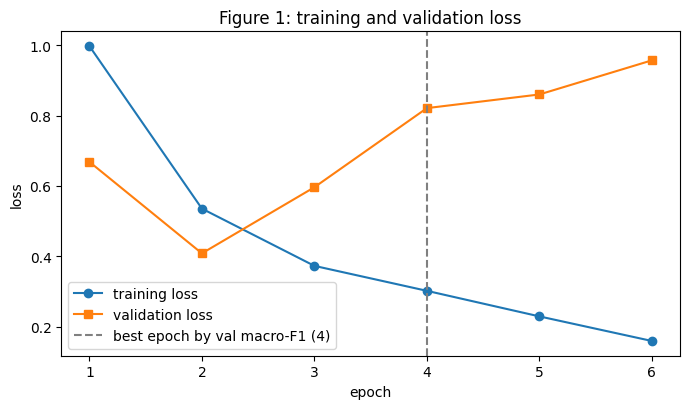

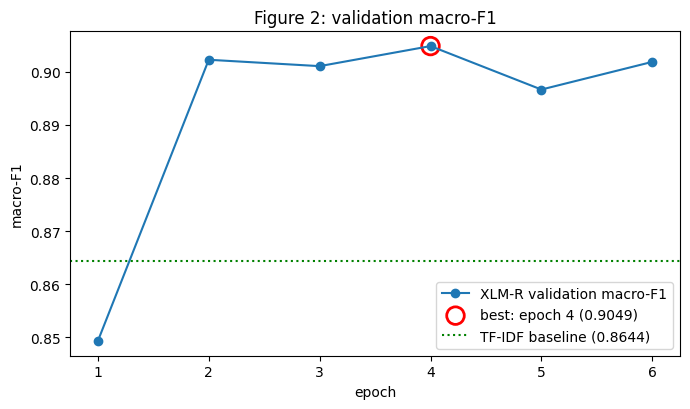

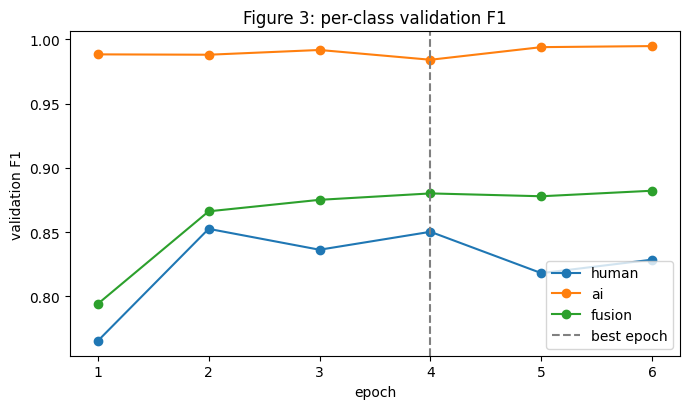

In [9]:
best_i = int(hist.val_macro_f1.idxmax()); best_ep = int(hist.epoch[best_i]); best_f1 = float(hist.val_macro_f1[best_i])
ticks = list(range(1, int(hist.epoch.max()) + 1))

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(hist.epoch, hist.train_loss, marker="o", label="training loss"); ax.plot(hist.epoch, hist.val_loss, marker="s", label="validation loss")
ax.axvline(best_ep, color="gray", ls="--", label=f"best epoch by val macro-F1 ({best_ep})"); ax.set_xticks(ticks); ax.set_xlabel("epoch"); ax.set_ylabel("loss"); ax.set_title("Figure 1: training and validation loss"); ax.legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig1_loss_curves.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(hist.epoch, hist.val_macro_f1, marker="o", label="XLM-R validation macro-F1"); ax.scatter([best_ep], [best_f1], s=160, facecolors="none", edgecolors="red", linewidths=2, label=f"best: epoch {best_ep} ({best_f1:.4f})")
ax.axhline(BASELINE_F1, color="green", ls=":", label=f"TF-IDF baseline ({BASELINE_F1})"); ax.set_xticks(ticks); ax.set_xlabel("epoch"); ax.set_ylabel("macro-F1"); ax.set_title("Figure 2: validation macro-F1"); ax.legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig2_val_macro_f1.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(7, 4.2))
for l in LABELS: ax.plot(hist.epoch, hist[f"f1_{l}"], marker="o", label=l)
ax.axvline(best_ep, color="gray", ls="--", label="best epoch"); ax.set_xticks(ticks); ax.set_xlabel("epoch"); ax.set_ylabel("validation F1"); ax.set_title("Figure 3: per-class validation F1"); ax.legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig3_per_class_f1.png", dpi=150); plt.show()

## 9. Best checkpoint evaluation
`load_best_model_at_end=True` has already loaded the checkpoint with the highest validation macro-F1. First, facts about the curves (printed from the numbers, no claim without evidence), then the full evaluation of that model on the 8,000 validation texts.

In [10]:
vl_min_ep = int(hist.epoch[hist.val_loss.idxmin()]); last = hist.iloc[-1]; at_min = hist[hist.epoch == vl_min_ep].iloc[0]
print(f"Best epoch (val macro-F1): {best_ep} -> {best_f1:.4f} | epochs trained: {len(hist)}")
print(f"Lowest validation loss at epoch {vl_min_ep} ({at_min.val_loss:.4f}); last epoch: {last.val_loss:.4f}")
if len(hist) > vl_min_ep:
    d_val, d_tr = last.val_loss - at_min.val_loss, last.train_loss - at_min.train_loss
    if d_val > 0.02 and d_tr < 0: print(f"-> after epoch {vl_min_ep} validation loss rose by {d_val:.3f} while training loss fell by {-d_tr:.3f}: the loss curves show the overfitting pattern (see whether macro-F1 also drops below).")
    else: print("-> no clear divergence between training and validation loss in the logged epochs.")
print(f"Macro-F1 at best epoch {best_f1:.4f} vs last epoch {last.val_macro_f1:.4f} (difference {last.val_macro_f1 - best_f1:+.4f})")
fb = hist.set_index("epoch").f1_fusion; print("fusion F1 per epoch:", fb.round(4).to_dict()); print(f"fusion F1: best epoch {int(fb.idxmax())} ({fb.max():.4f}); change from epoch {best_ep} to the last epoch: {fb.iloc[-1] - fb[best_ep]:+.4f}")
if len(hist) > 1 and EPOCHS == len(hist) and best_ep == len(hist): print("-> the best epoch is the last one: more epochs might still help (not tested here).")

Best epoch (val macro-F1): 4 -> 0.9049 | epochs trained: 6
Lowest validation loss at epoch 2 (0.4084); last epoch: 0.9570
-> after epoch 2 validation loss rose by 0.549 while training loss fell by 0.376: the loss curves show the overfitting pattern (see whether macro-F1 also drops below).
Macro-F1 at best epoch 0.9049 vs last epoch 0.9019 (difference -0.0030)
fusion F1 per epoch: {1: 0.7942, 2: 0.8662, 3: 0.8752, 4: 0.8802, 5: 0.8779, 6: 0.8823}
fusion F1: best epoch 6 (0.8823); change from epoch 4 to the last epoch: +0.0021


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


validation macro-F1 0.9049 | accuracy 0.9205 | (history value at best epoch: 0.9049, difference +0.00000 = fp16 / batching noise)

              precision    recall  f1-score   support

       human      0.883     0.820     0.850      1954
          ai      0.970     0.999     0.984      3592
      fusion      0.874     0.886     0.880      2454

    accuracy                          0.920      8000
   macro avg      0.909     0.902     0.905      8000
weighted avg      0.919     0.920     0.920      8000



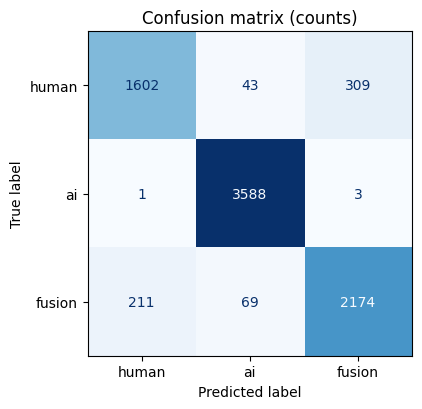

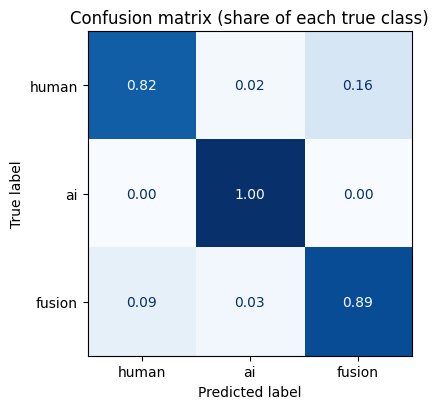

macro-F1 by language: {'de-DE': 0.911, 'en-EN': 0.903}


,n,macro_f1
domain,,
arxiv_papers,427.0,0.718
blog_authorship_corpus,1160.0,0.822
bundestag,1535.0,0.913
cnn_news,1290.0,0.942
euro_court_cases,862.0,0.867
gutenberg,199.0,0.566
house_of_commons,948.0,0.945
student_essays,1579.0,0.938


domains with fewer than 100 validation texts are omitted: []


In [11]:
seed_everything(); val_out = trainer.predict(va_ds)                          # best checkpoint, same 8,000 validation texts
logits_va = val_out.predictions; P_va = torch.softmax(torch.tensor(logits_va, dtype=torch.float32), dim=-1).numpy(); pred_va = P_va.argmax(1)
assert np.array_equal(val_out.label_ids, yva)
macro_f1_final, acc_final = f1_score(yva, pred_va, average="macro"), accuracy_score(yva, pred_va)
print(f"validation macro-F1 {macro_f1_final:.4f} | accuracy {acc_final:.4f} | (history value at best epoch: {best_f1:.4f}, difference {macro_f1_final-best_f1:+.5f} = fp16 / batching noise)\n")
print(classification_report(yva, pred_va, target_names=LABELS, digits=3))

for norm, fn, title in [(None, "cm_counts.png", "Confusion matrix (counts)"), ("true", "cm_normalized.png", "Confusion matrix (share of each true class)")]:
    fig, ax = plt.subplots(figsize=(5, 4.2)); ConfusionMatrixDisplay(confusion_matrix(yva, pred_va, normalize=norm), display_labels=LABELS).plot(cmap="Blues", ax=ax, colorbar=False, values_format=None if norm is None else ".2f")
    ax.set_title(title); plt.tight_layout(); plt.savefig(f"{OUT_DIR}/{fn}", dpi=150); plt.show()

d = va_df.assign(y=yva, p=pred_va)
print("macro-F1 by language:", d.groupby("lang")[["y", "p"]].apply(lambda g: f1_score(g.y, g.p, average="macro")).round(3).to_dict())
by_dom = d.groupby("domain")[["y", "p"]].apply(lambda g: pd.Series({"n": len(g), "macro_f1": f1_score(g.y, g.p, average="macro")}))
display(by_dom[by_dom.n >= 100].round(3)); print("domains with fewer than 100 validation texts are omitted:", by_dom[by_dom.n < 100].index.tolist())

## 10. Comparison with the TF-IDF baseline

In [12]:
cmp = pd.DataFrame({"Model": ["TF-IDF + Logistic Regression", f"XLM-RoBERTa (best epoch = {best_ep})"], "Validation macro-F1": [BASELINE_F1, macro_f1_final]})
display(cmp.round(4)); print(f"absolute difference in macro-F1 (encoder - baseline): {macro_f1_final - BASELINE_F1:+.4f}")
f1_enc = dict(zip(LABELS, f1_score(yva, pred_va, average=None, labels=[0, 1, 2])))
display(pd.DataFrame({"baseline F1": BASELINE_CLASS_F1, "encoder F1": f1_enc, "difference": {l: f1_enc[l] - BASELINE_CLASS_F1[l] for l in LABELS}}).round(4))
print("Note: both models are scored on the same 8,000 validation texts with one seed; differences of roughly 0.005 or less should not be read as real.")

,Model,Validation macro-F1
0,TF-IDF + Logistic Regression,0.8644
1,XLM-RoBERTa (best epoch = 4),0.9049


absolute difference in macro-F1 (encoder - baseline): +0.0405


,baseline F1,encoder F1,difference
human,0.801,0.8503,0.0493
ai,0.986,0.9841,-0.0019
fusion,0.806,0.8802,0.0742


Note: both models are scored on the same 8,000 validation texts with one seed; differences of roughly 0.005 or less should not be read as real.


## 11. Test predictions and Kaggle submission
Same tokenization (head + tail) and the best checkpoint, predicted in batches. The submission is checked against `sample_submission.csv`; it is **not** uploaded automatically.

In [13]:
seed_everything(); te_out = trainer.predict(te_ds)
P_te = torch.softmax(torch.tensor(te_out.predictions, dtype=torch.float32), dim=-1).numpy(); pred_te = P_te.argmax(1)
assert len(pred_te) == len(test) == 25000 and P_te.shape == (25000, 3)

submission = pd.DataFrame({"id": test.id.values, "label": [id2label[i] for i in pred_te]}).set_index("id").loc[sub_tmpl.id].reset_index()
assert list(submission.columns) == ["id", "label"] and len(submission) == 25000 and submission.id.is_unique
assert submission.id.tolist() == sub_tmpl.id.tolist() and submission.label.notna().all() and submission.label.isin(LABELS).all()
submission.to_csv(f"{OUT_DIR}/sub_xlmr_encoder.csv", index=False)
print("saved sub_xlmr_encoder.csv | predicted label shares:", submission.label.value_counts(normalize=True).round(3).to_dict()); submission.head()

saved sub_xlmr_encoder.csv | predicted label shares: {'ai': 0.53, 'fusion': 0.242, 'human': 0.228}


,id,label
0,8ff2d1,ai
1,a261cf,human
2,ad5614,fusion
3,3a23ac,ai
4,28b4e5,ai


## 12. Save artifacts
Everything needed for later ensembles: probabilities in the class order `human, ai, fusion` (same as the TF-IDF baseline), ids, labels, the best model with its tokenizer, the history and the figures.

In [14]:
classes = np.array(LABELS)
np.savez(f"{OUT_DIR}/xlmr_probs.npz", va_ids=va_df.id.values.astype(str), test_ids=test.id.values.astype(str), yva=yva, P_va=P_va.astype(np.float32), P_te=P_te.astype(np.float32), classes=classes)
chk = np.load(f"{OUT_DIR}/xlmr_probs.npz", allow_pickle=True); assert list(chk["classes"]) == LABELS and chk["P_va"].shape == (8000, 3) and chk["P_te"].shape == (25000, 3)
assert np.array_equal(chk["P_va"].argmax(1), pred_va) or (chk["P_va"].argmax(1) != pred_va).mean() < 1e-3

pd.DataFrame({"id": va_df.id, "y_true": [id2label[i] for i in yva], "y_pred": [id2label[i] for i in pred_va], **{f"p_{l}": P_va[:, i] for i, l in enumerate(LABELS)}}).to_csv(f"{OUT_DIR}/xlmr_val_predictions.csv", index=False)
BEST_DIR = f"{OUT_DIR}/best_model"; trainer.save_model(BEST_DIR); tok.save_pretrained(BEST_DIR)
json.dump(dict(model=MODEL_NAME, seed=SEED, n_sub=N_SUB, val_frac=VAL_FRAC, val_id_fingerprint=FINGERPRINT, label2id=label2id, classes=LABELS, max_len=MAX_LEN, head_tokens=HEAD_TOKENS, tail_tokens=TAIL_TOKENS,
               epochs_max=EPOCHS, epochs_trained=int(len(hist)), best_epoch=best_ep, best_val_macro_f1=best_f1, lr=LR, weight_decay=WEIGHT_DECAY, warmup=WARMUP, per_device_bs=PER_DEVICE_BS,
               grad_accum=ACCUM, n_gpu=N_GPU, fp16=HAS_CUDA, early_stopping=EARLY_STOPPING, torch=torch.__version__, transformers=transformers.__version__),
          open(f"{OUT_DIR}/run_config.json", "w"), indent=1)
if CLEAN_CHECKPOINTS: shutil.rmtree(CKPT_DIR, ignore_errors=True); print("removed the large Trainer checkpoints (best model is in best_model/)")
for p in sorted(glob.glob(f"{OUT_DIR}/*")): print(os.path.basename(p), f"{(os.path.getsize(p) if os.path.isfile(p) else sum(os.path.getsize(os.path.join(r, f)) for r, _, fs in os.walk(p) for f in fs)) / 1e6:.1f} MB")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

removed the large Trainer checkpoints (best model is in best_model/)
best_model 1129.3 MB
cm_counts.png 0.0 MB
cm_normalized.png 0.0 MB
encoder_training_history.csv 0.0 MB
fig1_loss_curves.png 0.1 MB
fig2_val_macro_f1.png 0.1 MB
fig3_per_class_f1.png 0.1 MB
run_config.json 0.0 MB
sub_xlmr_encoder.csv 0.3 MB
xlmr_probs.npz 1.3 MB
xlmr_val_predictions.csv 0.4 MB


## 13. Conclusions

In [15]:
print(f"XLM-RoBERTa base, head+tail 512 tokens, up to {EPOCHS} epochs ({len(hist)} trained).")
print(f"Best epoch {best_ep}: validation macro-F1 {macro_f1_final:.4f} vs TF-IDF {BASELINE_F1} ({macro_f1_final - BASELINE_F1:+.4f}).")
print("Per-class F1 (human / ai / fusion):", {l: round(float(v), 3) for l, v in f1_enc.items()}, "| baseline:", BASELINE_CLASS_F1)
print("Remember: the best epoch was chosen on the validation set, and validation may contain siblings of training texts, so the leaderboard score is likely somewhat lower.")

XLM-RoBERTa base, head+tail 512 tokens, up to 6 epochs (6 trained).
Best epoch 4: validation macro-F1 0.9049 vs TF-IDF 0.8644 (+0.0405).
Per-class F1 (human / ai / fusion): {'human': 0.85, 'ai': 0.984, 'fusion': 0.88} | baseline: {'human': 0.801, 'ai': 0.986, 'fusion': 0.806}
Remember: the best epoch was chosen on the validation set, and validation may contain siblings of training texts, so the leaderboard score is likely somewhat lower.


### Conclusions

I fine-tuned XLM-RoBERTa-base for six epochs on 32,000 training texts and evaluated it on the same 8,000 validation texts used for the TF-IDF baseline. Long documents were handled using head + tail truncation to 512 tokens.

**The best overall performance was achieved at epoch 4**, with a validation macro-F1 of **0.9049** and accuracy of **0.9205**. This outperformed the TF-IDF Logistic Regression baseline (macro-F1 = 0.8644) by **0.0405**, demonstrating the benefit of contextual representations for this classification task.

The largest improvement was observed for the `fusion` class, where F1 increased from 0.806 to 0.880. Human classification also improved from 0.801 to 0.850, while AI classification remained consistently strong (F1 ≈ 0.984).

Training for more epochs did not consistently improve overall performance. Validation macro-F1 increased substantially between epochs 1 and 2, then fluctuated, reaching its maximum at epoch 4. Meanwhile, training loss continuously decreased, whereas validation loss reached its minimum at epoch 2 and subsequently increased. This indicates signs of overfitting and demonstrates why selecting the best checkpoint is preferable to using the final epoch automatically.

Although `fusion` F1 reached its highest value at epoch 6 (0.8823), the improvement over epoch 4 (0.8802) was small and accompanied by slightly worse overall macro-F1.

Performance also varied across domains. The encoder performed well on news, parliamentary texts, and student essays, but substantially worse on Gutenberg texts (macro-F1 = 0.566). Performance was relatively consistent across languages (German: 0.911; English: 0.903).